# Linear Regression from Scratch on Housing Dataset

In this notebook, we implement and evaluate a custom Linear Regression model trained using batch gradient descent with L2 regularization to predict house prices.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from linear_regression import LinearRegression

### 1. Loading and Inspecting the Data

We load the housing dataset and inspect the first few rows to explore the available features.

In [18]:
df = pd.read_csv("../data/housing_data.csv")

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea
0,13300000,7420,4,2,3,1,0,0,0,1,2,1
1,12250000,8960,4,4,4,1,0,0,0,1,3,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1
4,11410000,7420,4,1,2,1,1,1,0,1,2,0


### 2. Feature and Target Separation

We separate the target variable (price) from the 11 input features.

In [3]:
X = df.drop("price", axis=1).values
y = df["price"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (545, 11)
y shape: (545,)


### 3. Shuffling and Train Test Split

Because the dataset was sorted by price, we randomly shuffle the indices before taking an 80 percent training and 20 percent testing split to avoid sorted data bias.

In [4]:
np.random.seed(42)

indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

### 4. Feature Standardization

We standardize the features and target using training statistics so that gradient descent converges smoothly.

In [5]:

X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std



y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train - y_mean) / y_std

### 5. Training the Custom Linear Regression Model

We instantiate our custom LinearRegression class and fit it on the scaled training data.

In [6]:
model = LinearRegression()

In [7]:
model.fit(X_train_scaled, y_train_scaled)

### 6. Inspecting Learned Parameters and Cost Convergence

We inspect the learned weights and plot the cost history across iterations to confirm proper convergence.

In [8]:
print("Weights:")
print(model.w)

print("\nBias:")
print(model.b)

Weights:
[0.29260599 0.06209202 0.26845137 0.21710284 0.08819432 0.05628211
 0.07380316 0.08747733 0.2430862  0.12759107 0.16360142]

Bias:
-1.6685939072852626e-16


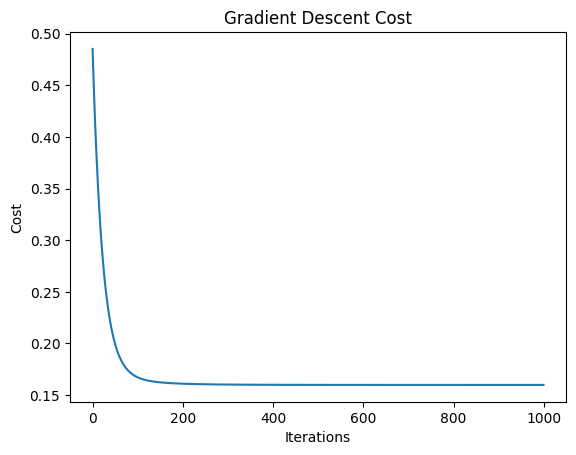

In [9]:
plt.plot(model.cost_history)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Cost")

plt.show()

In [10]:
print("Initial cost:", model.cost_history[0])
print("Final cost:", model.cost_history[-1])

Initial cost: 0.4852735786859427
Final cost: 0.15978337397588743


### 7. Generating Predictions and Visualizing Results

We predict prices for the test set, unscale them back to dollar values, and visualize actual versus predicted prices.

In [11]:
y_pred_scaled = model.predict(X_test_scaled)

In [ ]:
y_pred = y_pred_scaled * y_std + y_mean

In [13]:
for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print("Actual:", actual, "Predicted:", predicted)

Actual: 9870000 Predicted: 7468729.635229195
Actual: 3990000 Predicted: 2996863.3630035697
Actual: 3850000 Predicted: 2817652.834152735
Actual: 7000000 Predicted: 7047097.419391183
Actual: 4200000 Predicted: 3971268.773488031
Actual: 9240000 Predicted: 6123688.859170806
Actual: 5523000 Predicted: 5014628.223824967
Actual: 7875000 Predicted: 6100087.677415641
Actual: 3633000 Predicted: 4168767.625661182
Actual: 5110000 Predicted: 5519449.409466432


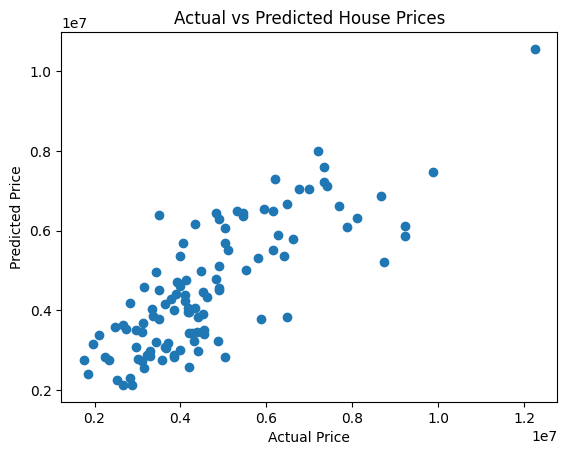

In [15]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

### 8. Applying Log Transformation on Target Variable

House prices are right skewed and prices compound multiplicatively. We apply a natural log transformation on the target variable and retrain our model.

In [19]:
y_train_log = np.log(y_train)

In [20]:
y_log_mean = y_train_log.mean()
y_log_std = y_train_log.std()

y_train_log_scaled = (y_train_log - y_log_mean) / y_log_std

In [21]:
model = LinearRegression()

In [22]:
model.fit(X_train_scaled, y_train_log_scaled)

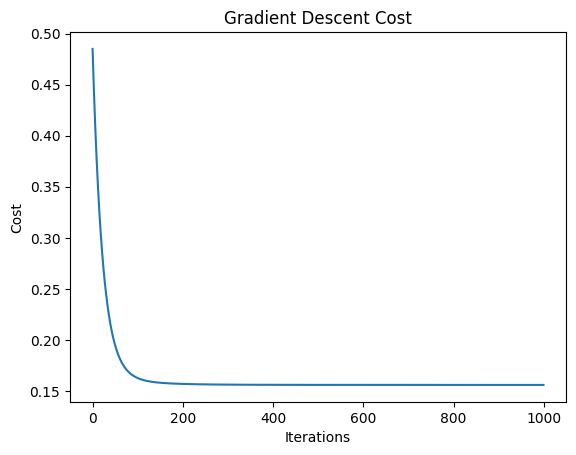

In [23]:
plt.plot(model.cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Cost")
plt.show()

### 9. Predicting and Evaluating the Log Transformed Model

We generate predictions, invert the log transformation using the exponential function, and evaluate the final MAPE and R2 score.

In [24]:
y_pred_log_scaled = model.predict(X_test_scaled)

In [25]:
y_pred_log = y_pred_log_scaled * y_log_std + y_log_mean

In [26]:
y_pred = np.exp(y_pred_log)

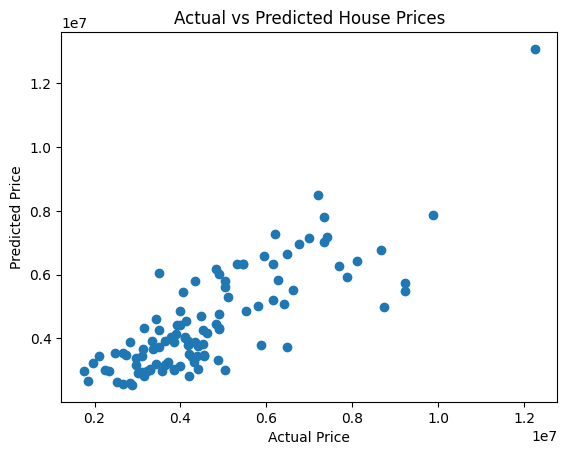

In [29]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [33]:
mape = np.mean(
    np.abs((y_test - y_pred) / y_test)
) * 100
print(mape)

18.568743059036922


In [32]:
ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2 = 1 - (ss_res / ss_tot)
print(r2)

0.6508107861180505


## Conclusion

We implemented Linear Regression from scratch with batch gradient descent. First we trained on raw prices and achieved about 20 percent MAPE. Because house prices are right skewed and have high dollar variance, standard linear regression is heavily affected by expensive houses.

Applying a natural log transformation to the target price compressed the price range and aligned our loss function with percentage errors. After converting predictions back to dollars, MAPE improved to 18.57 percent and R2 reached 0.65.